In [1]:
!pip install pandas --quiet
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV,learning_curve
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [2]:
accident_df=pd.read_csv("/content/RTA Dataset.csv (1).zip")

In [3]:
accident_df.shape

(12316, 32)

In [4]:
accident_df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [5]:
accident_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allignment              12

In [6]:
accident_df.describe()

,Number_of_vehicles_involved,Number_of_casualties
count,12316.000000,12316.000000
mean,2.040679,1.548149
std,0.688790,1.007179
min,1.000000,1.000000
25%,2.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,2.000000
max,7.000000,8.000000


In [7]:
accident_df.isnull().sum()

,0
Time,0
Day_of_week,0
Age_band_of_driver,0
Sex_of_driver,0
Educational_level,741
Vehicle_driver_relation,579
Driving_experience,829
Type_of_vehicle,950
Owner_of_vehicle,482
Service_year_of_vehicle,3928


In [8]:
cat_cols=['Driving_experience','Service_year_of_vehicle','Educational_level','Fitness_of_casuality',
          'Work_of_casuality','Vehicle_movement','Type_of_collision','Road_surface_type',
          'Area_accident_occured','Lanes_or_Medians','Road_allignment','Types_of_Junction',
          'Vehicle_driver_relation','Type_of_vehicle','Owner_of_vehicle','Defect_of_vehicle']
for cols in cat_cols:
  accident_df[cols].fillna(accident_df[cols].mode()[0],inplace=True)

/tmp/ipykernel_3125/2917594670.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  accident_df[cols].fillna(accident_df[cols].mode()[0],inplace=True)


In [9]:
accident_df.isnull().sum()

,0
Time,0
Day_of_week,0
Age_band_of_driver,0
Sex_of_driver,0
Educational_level,0
Vehicle_driver_relation,0
Driving_experience,0
Type_of_vehicle,0
Owner_of_vehicle,0
Service_year_of_vehicle,0


In [10]:
accident_df.duplicated().sum()

np.int64(0)

In [11]:
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Automobile", value="car")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Lorry (41?100Q)", value="Goods vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Pick up upto 10Q", value="Goods vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Public (12 seats)", value="Bus")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Stationwagen", value="car")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Lorry (11?40Q)", value="Goods vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Public (13?45 seats)", value="Bus")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Public (> 45 seats)", value="Bus")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Long lorry", value="Goods vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Taxi", value="car")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Motorcycle", value="Motorcycle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Special vehicle", value="Special vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Ridden horse", value="Animal vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Turbo", value="other vehicle")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Bajaj", value=" Three-wheeler")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Bicycle", value="Two-wheeler")
accident_df['Type_of_vehicle'] = accident_df['Type_of_vehicle'].replace(to_replace="Other", value="other vehicle")


In [12]:
accident_df['Type_of_vehicle'].value_counts()/accident_df.shape[0]*100

,count
Type_of_vehicle,
car,41.466385
Goods vehicle,31.836635
Bus,13.372848
other vehicle,10.181877
Motorcycle,1.437155
Special vehicle,0.682040
Animal vehicle,0.617083
Three-wheeler,0.235466
Two-wheeler,0.170510


In [13]:
accident_df['Service_year_of_vehicle'].value_counts()/accident_df.shape[0]*100

,count
Service_year_of_vehicle,
Unknown,55.302046
2-5yrs,14.550179
Above 10yr,10.750244
5-10yrs,10.392985
1-2yr,6.714842
Below 1yr,2.289704


In [14]:
accident_df['Service_year_of_vehicle'] = accident_df['Service_year_of_vehicle'].replace(to_replace="2-5yrs", value="2-5")
accident_df['Service_year_of_vehicle'] = accident_df['Service_year_of_vehicle'].replace(to_replace="Above 10yr", value="Above 10")
accident_df['Service_year_of_vehicle'] = accident_df['Service_year_of_vehicle'].replace(to_replace="5-10yrs", value="5-10")
accident_df['Service_year_of_vehicle'] = accident_df['Service_year_of_vehicle'].replace(to_replace="1-2yr", value="1-2")
accident_df['Service_year_of_vehicle'] = accident_df['Service_year_of_vehicle'].replace(to_replace="Below 1yr", value="Below 1")



In [15]:
accident_df['Service_year_of_vehicle'].value_counts()/accident_df.shape[0]*100

,count
Service_year_of_vehicle,
Unknown,55.302046
2-5,14.550179
Above 10,10.750244
5-10,10.392985
1-2,6.714842
Below 1,2.289704


In [16]:
accident_df['Weather_conditions'].value_counts()/accident_df.shape[0]*100

,count
Weather_conditions,
Normal,81.706723
Raining,10.807080
Other,2.403378
Unknown,2.370900
Cloudy,1.014940
Windy,0.795713
Snow,0.495291
Raining and Windy,0.324781
Fog or mist,0.081195


In [17]:
accident_df['Accident_severity'].value_counts()/accident_df.shape[0]*100

,count
Accident_severity,
Slight Injury,84.564794
Serious Injury,14.152322
Fatal injury,1.282884


In [18]:
accident_df['Accident_seriousness'] = accident_df['Accident_severity']
accident_df['Accident_seriousness'] = accident_df['Accident_seriousness'].replace(to_replace="Slight",value="Not Serious")
accident_df['Accident_seriousness'] = accident_df['Accident_seriousness'].replace(to_replace="Serious",value="Serious")
accident_df['Accident_seriousness'] = accident_df['Accident_seriousness'].replace(to_replace="Fatal",value="Fatal")
accident_df.shape

(12316, 33)

In [19]:
accident_df['Accident_seriousness'].value_counts()/accident_df.shape[0]*100

,count
Accident_seriousness,
Slight Injury,84.564794
Serious Injury,14.152322
Fatal injury,1.282884


In [20]:
accident_df['Light_conditions'].value_counts()/accident_df.shape[0]*100

,count
Light_conditions,
Daylight,71.435531
Darkness - lights lit,26.680741
Darkness - no lighting,1.558948
Darkness - lights unlit,0.324781


In [21]:
accident_df.Accident_seriousness.value_counts()

,count
Accident_seriousness,
Slight Injury,10415
Serious Injury,1743
Fatal injury,158


In [22]:
accident_df['Cause_of_accident'].value_counts()/accident_df.shape[0]*100

,count
Cause_of_accident,
No distancing,18.374472
Changing lane to the right,14.680091
Changing lane to the left,11.960052
Driving carelessly,11.383566
No priority to vehicle,9.800260
Moving Backward,9.231893
No priority to pedestrian,5.854173
Other,3.702501
Overtaking,3.491393


In [23]:
fig=px.histogram(accident_df,x='Day_of_week',nbins=7,title='Accidents Daily')
fig.update_layout(bargap=0.1)
fig.show()

In [24]:
fig=px.histogram(accident_df,x='Age_band_of_driver',nbins=5,title='Distribution of Driver Age')
fig.update_layout(bargap=0.1)
fig.show()

In [25]:
fig=px.histogram(accident_df,x='Educational_level',nbins=7,title='Education of Driver')
fig.update_layout(bargap=0.1)
fig.show()

In [26]:
accident_df['Time'] = pd.to_datetime(accident_df['Time'])
fig = px.histogram(accident_df,x='Time',nbins=12,title='Time of Accident')
fig.update_layout(bargap=0.1)
fig.show()

/tmp/ipykernel_3125/393642861.py:1: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



In [27]:
def bucket_hour(h):
    if 5 <= h < 12: return "Morning"
    elif 12 <= h < 17: return "Afternoon"
    elif 17 <= h < 21: return "Evening"
    else: return "Night"

accident_df['Time'] = accident_df['Time'].dt.hour.apply(bucket_hour)

In [28]:
fig = px.histogram(accident_df,x='Type_of_vehicle',title='Type of vehicle')
fig.update_layout(bargap=0.1)
fig.show()

In [29]:
fig = px.histogram(accident_df,x='Weather_conditions',title='Weather conditions')
fig.update_layout(bargap=0.1)
fig.show()

In [30]:
fig = px.histogram(accident_df,x='Light_conditions',title='Light conditions')
fig.update_layout(bargap=0.1)
fig.show()

In [31]:
fig = px.histogram(accident_df,x='Road_surface_conditions',title='Road surface conditions')
fig.update_layout(bargap=0.1)
fig.show()

In [32]:
fig = px.histogram(accident_df,x='Cause_of_accident',title='Cause of accident')
fig.update_layout(bargap=0.1)
fig.show()

In [33]:
fig = px.histogram(accident_df,x='Accident_severity',title='Accident severity')
fig.update_layout(bargap=0.1)
fig.show()

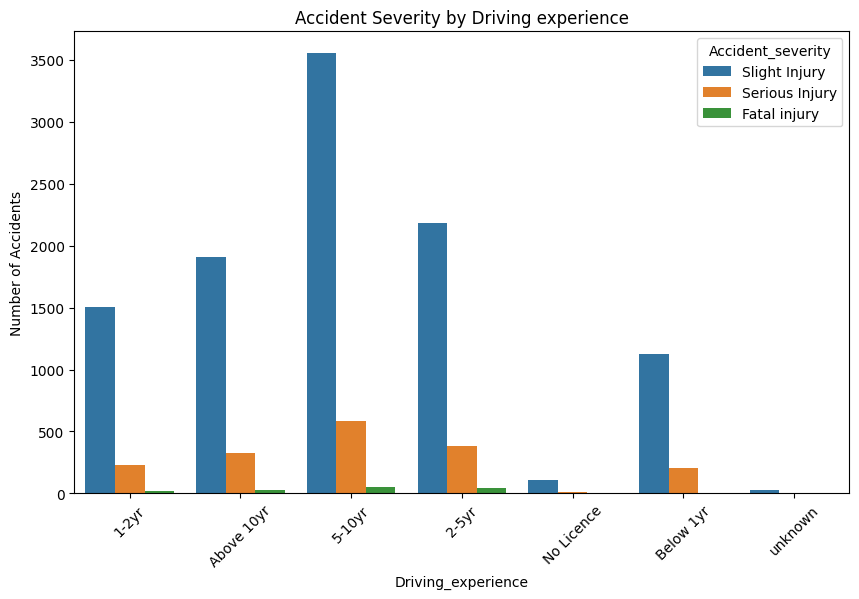

In [34]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Driving_experience',hue='Accident_severity')
plt.title('Accident Severity by Driving experience')
plt.xlabel('Driving_experience')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.show()

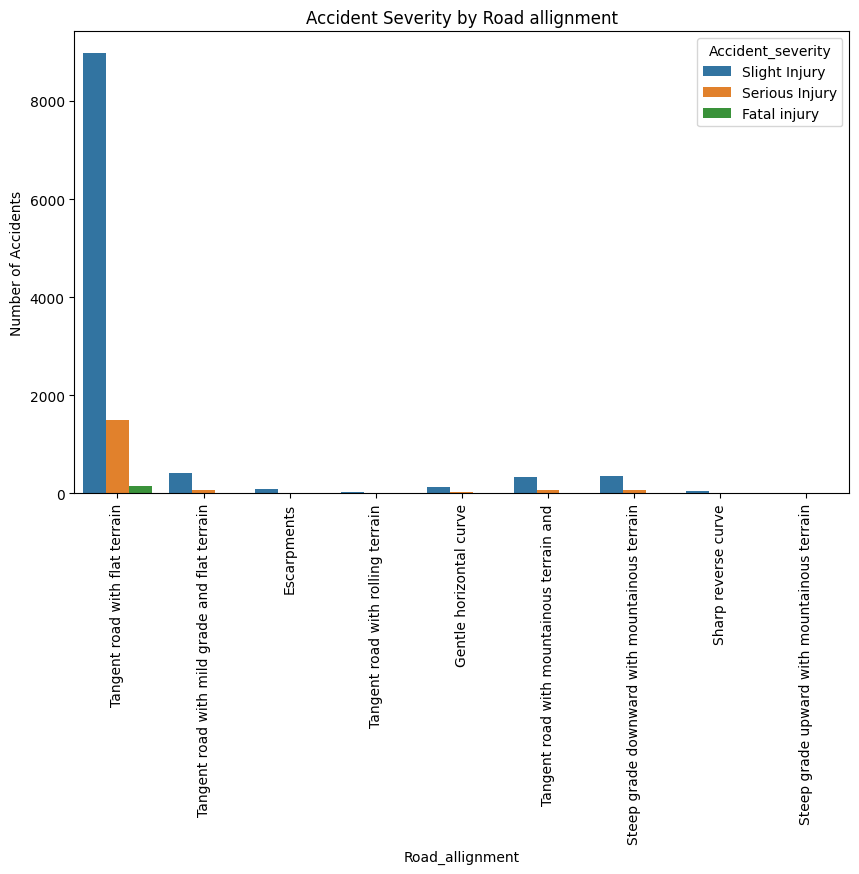

In [35]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Road_allignment',hue='Accident_severity')
plt.title('Accident Severity by Road allignment')
plt.xlabel('Road_allignment')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=90)
plt.show()

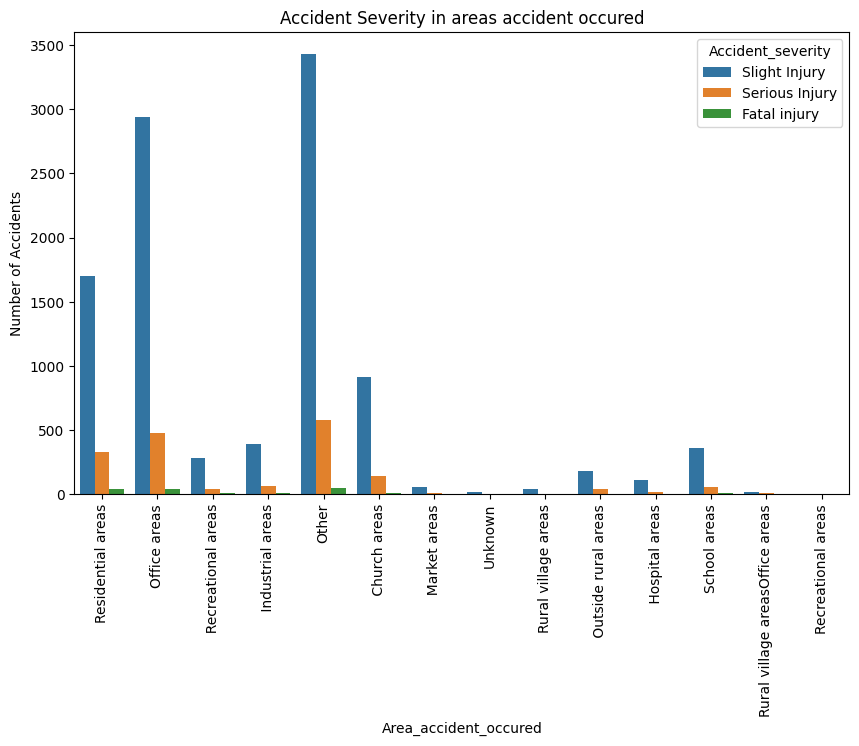

In [36]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Area_accident_occured',hue='Accident_severity')
plt.title('Accident Severity in areas accident occured')
plt.xlabel('Area_accident_occured')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=90)
plt.show()

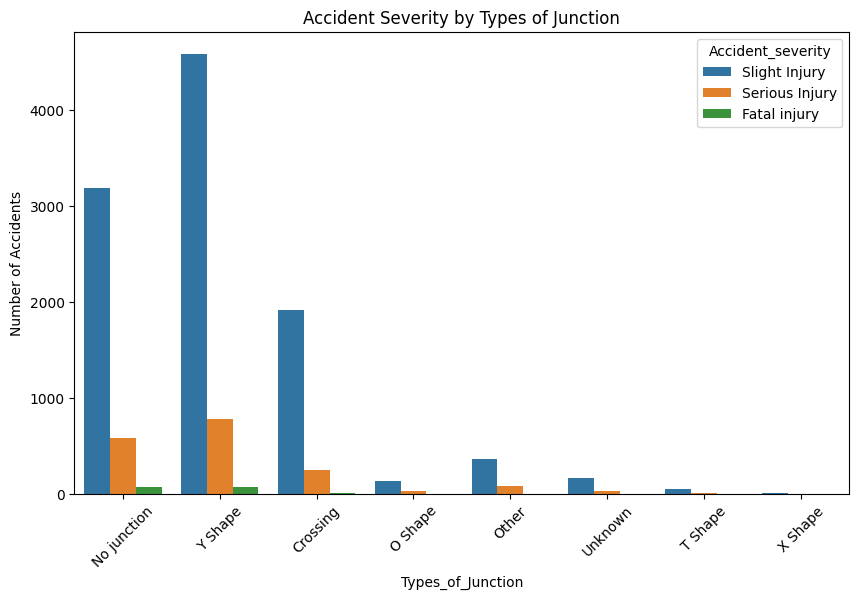

In [37]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Types_of_Junction',hue='Accident_severity')
plt.title('Accident Severity by Types of Junction')
plt.xlabel('Types_of_Junction')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.show()

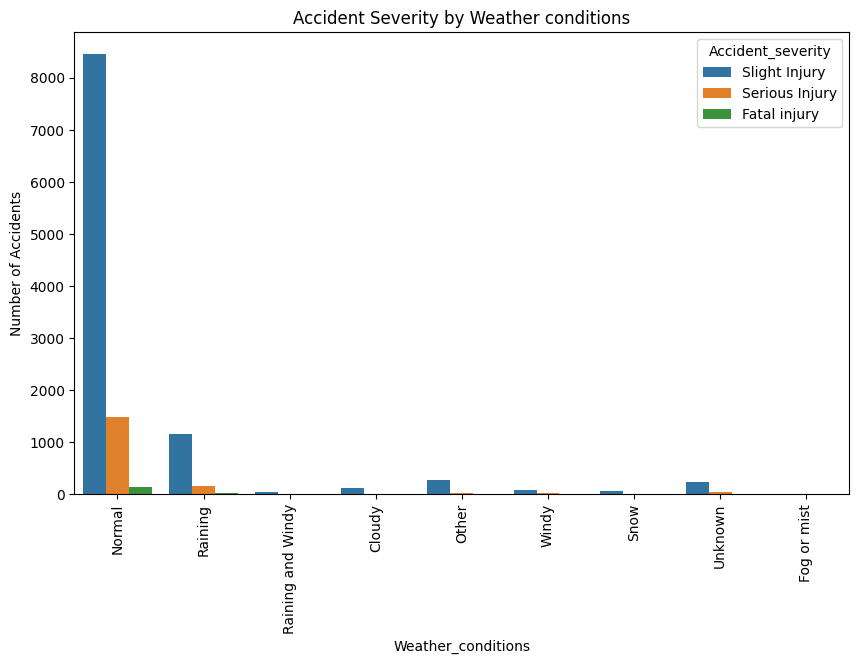

In [38]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Weather_conditions',hue='Accident_severity')
plt.title('Accident Severity by Weather conditions')
plt.xlabel('Weather_conditions')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=90)
plt.show()

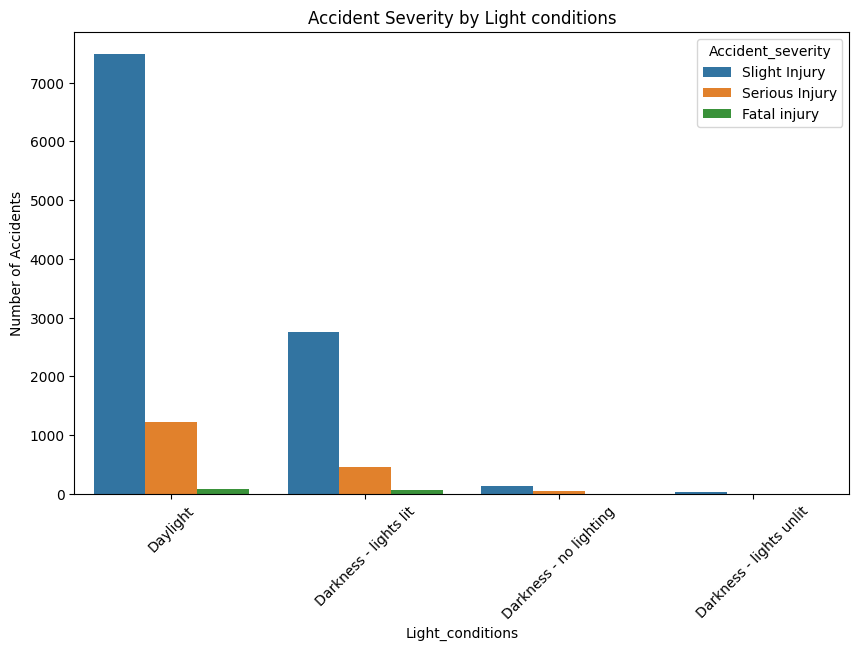

In [39]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Light_conditions',hue='Accident_severity')
plt.title('Accident Severity by Light conditions')
plt.xlabel('Light_conditions')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.show()

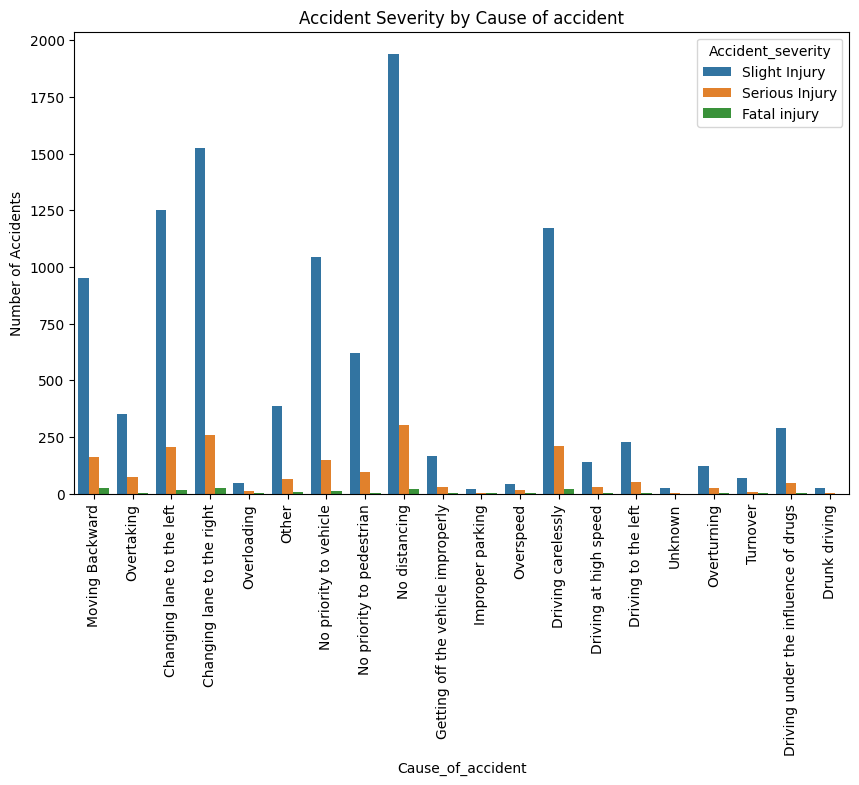

In [40]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Cause_of_accident',hue='Accident_severity')
plt.title('Accident Severity by Cause of accident')
plt.xlabel('Cause_of_accident')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=90)
plt.show()

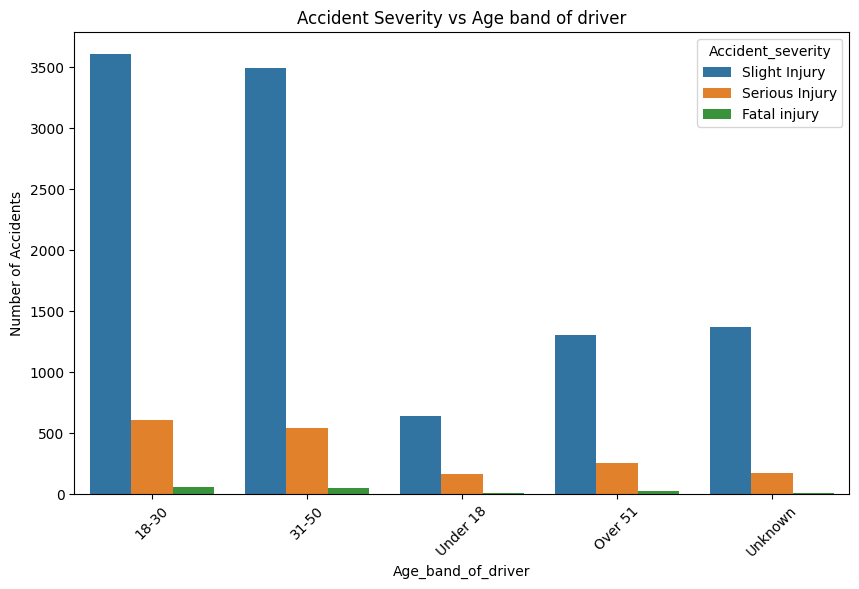

In [41]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Age_band_of_driver',hue='Accident_severity')
plt.title('Accident Severity vs Age band of driver')
plt.xlabel('Age_band_of_driver')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.show()

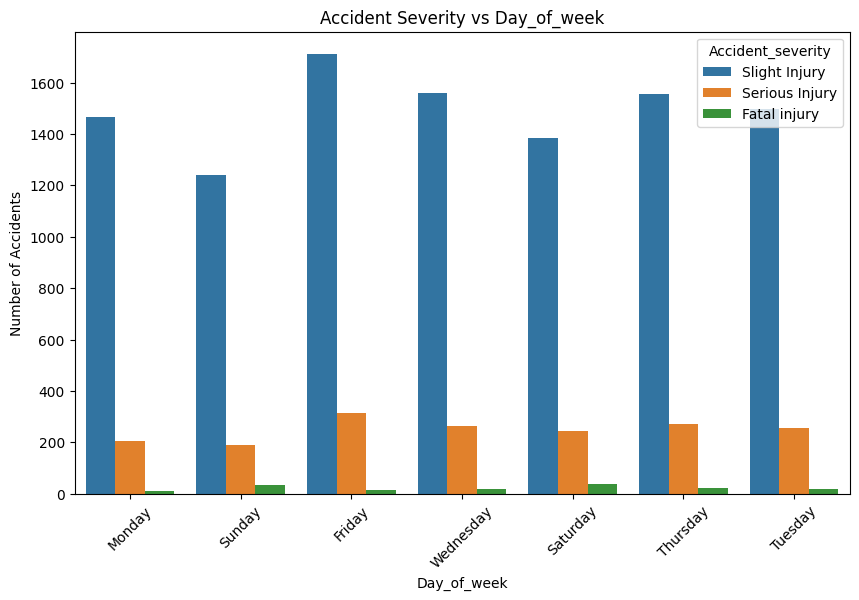

In [42]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Day_of_week',hue='Accident_severity')
plt.title('Accident Severity vs Day_of_week')
plt.xlabel('Day_of_week')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.show()

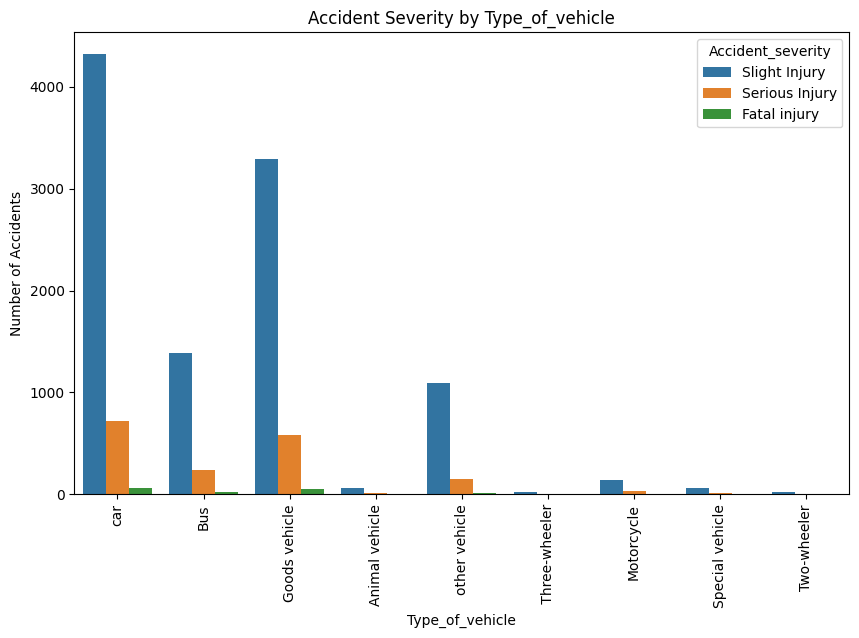

In [43]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Type_of_vehicle',hue='Accident_severity')
plt.title('Accident Severity by Type_of_vehicle')
plt.xlabel('Type_of_vehicle')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=90)
plt.show()

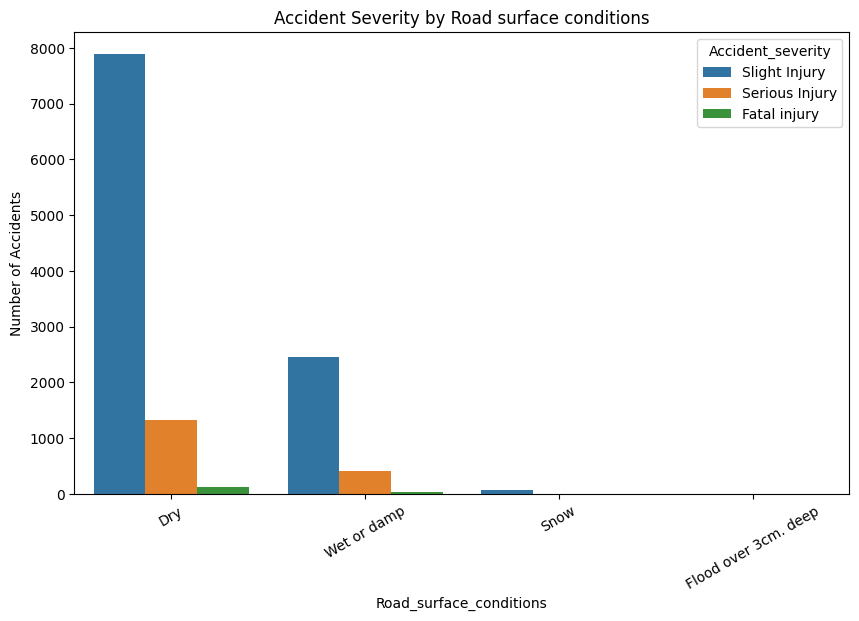

In [44]:
plt.figure(figsize=(10,6))
sns.countplot(data=accident_df,x='Road_surface_conditions',hue='Accident_severity')
plt.title('Accident Severity by Road surface conditions')
plt.xlabel('Road_surface_conditions')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=30)
plt.show()

In [45]:
fig=px.histogram(accident_df,x='Number_of_vehicles_involved',marginal='box',color='Accident_severity',
                 color_discrete_sequence=['green','grey','blue'],title='Accident Severity vs Number of vehicles involved')
fig.update_layout(bargap=0.1)
fig.show()

In [46]:
fig=px.histogram(accident_df,x='Number_of_casualties',marginal='box',color='Accident_severity',
                 color_discrete_sequence=['green','grey','blue'],title='Accident Severity vs Number of casualties')
fig.update_layout(bargap=0.1)
fig.show()

In [47]:
import scipy.stats as stats

In [48]:
accident_df.columns

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Number_of_vehicles_involved',
       'Number_of_casualties', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity', 'Accident_seriousness'],
      dtype='object')

In [49]:
accident_df['Age_band_of_driver'].value_counts()/accident_df.shape[0]*100

,count
Age_band_of_driver,
18-30,34.678467
31-50,33.184475
Over 51,12.869438
Unknown,12.569016
Under 18,6.698603


In [50]:
cat_cols=accident_df.select_dtypes(include='object').columns
print(cat_cols)

Index(['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver',
       'Educational_level', 'Vehicle_driver_relation', 'Driving_experience',
       'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians',
       'Road_allignment', 'Types_of_Junction', 'Road_surface_type',
       'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
       'Type_of_collision', 'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity',
       'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement',
       'Cause_of_accident', 'Accident_severity', 'Accident_seriousness'],
      dtype='object')


In [51]:
import joblib

categorical_features = ['Time', 'Day_of_week', 'Age_band_of_driver', 'Type_of_vehicle',
                         'Area_accident_occured', 'Types_of_Junction', 'Light_conditions',
                         'Weather_conditions', 'Age_band_of_casualty']
categories = {col: sorted(accident_df[col].dropna().unique().tolist()) for col in categorical_features}
joblib.dump(categories, "categories.joblib")

['categories.joblib']

In [52]:
accident_df=pd.get_dummies(accident_df,columns=['Time', 'Day_of_week', 'Age_band_of_driver',
       'Type_of_vehicle', 'Area_accident_occured', 'Types_of_Junction',  'Light_conditions',
        'Weather_conditions','Age_band_of_casualty'],drop_first=True)

In [53]:
accident_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 81 columns):
 #   Column                                                 Non-Null Count  Dtype 
---  ------                                                 --------------  ----- 
 0   Sex_of_driver                                          12316 non-null  object
 1   Educational_level                                      12316 non-null  object
 2   Vehicle_driver_relation                                12316 non-null  object
 3   Driving_experience                                     12316 non-null  object
 4   Owner_of_vehicle                                       12316 non-null  object
 5   Service_year_of_vehicle                                12316 non-null  object
 6   Defect_of_vehicle                                      12316 non-null  object
 7   Lanes_or_Medians                                       12316 non-null  object
 8   Road_allignment                                        1

In [54]:
le=LabelEncoder()

In [55]:
accident_df['Accident_severity']=le.fit_transform(accident_df['Accident_severity'])

In [56]:
X=accident_df.drop(['Sex_of_driver','Educational_level', 'Vehicle_driver_relation',
                    'Driving_experience','Owner_of_vehicle', 'Service_year_of_vehicle',
       'Defect_of_vehicle',  'Lanes_or_Medians','Road_allignment',  'Road_surface_type',
       'Road_surface_conditions', 'Type_of_collision',  'Vehicle_movement', 'Casualty_class',
       'Sex_of_casualty', 'Casualty_severity','Work_of_casuality', 'Fitness_of_casuality',
        'Pedestrian_movement','Cause_of_accident','Accident_severity','Accident_seriousness'],axis=1)
y=accident_df['Accident_severity']

Text(0.5, 1.0, 'Correlation Matrix')

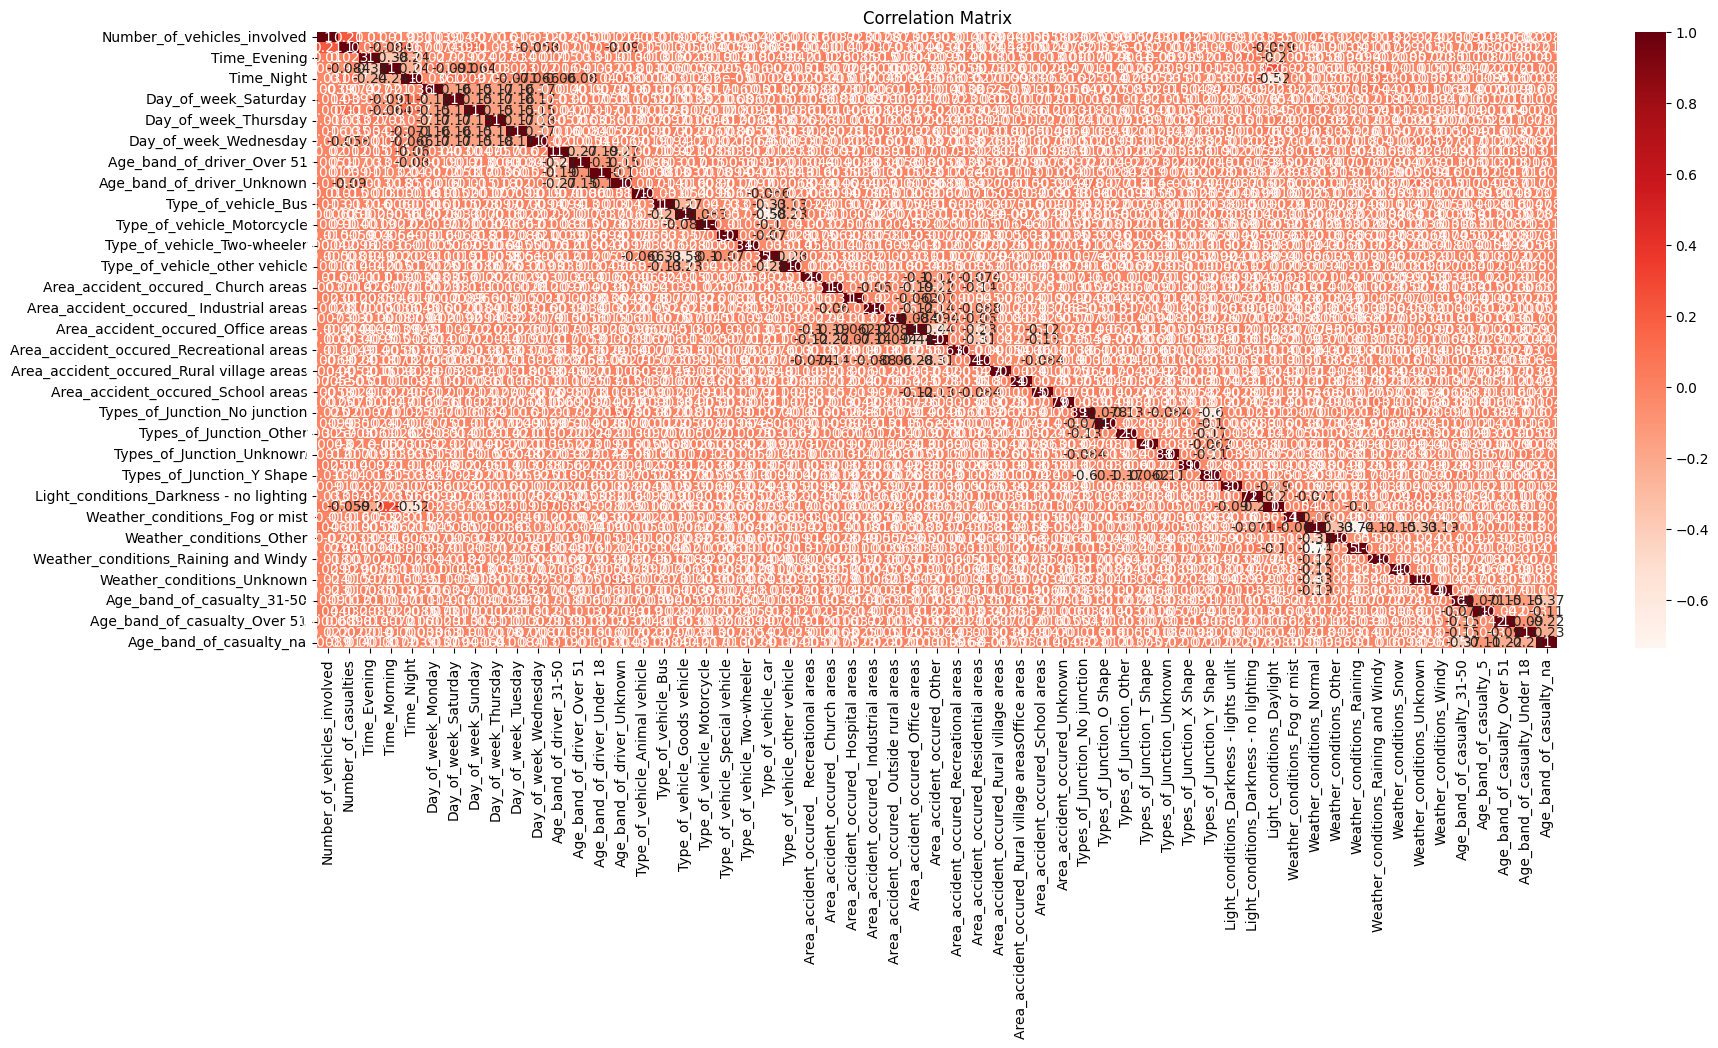

In [57]:
plt.subplots(figsize=(20,8))
sns.heatmap(X.corr(),cmap='Reds',annot=True)
plt.title('Correlation Matrix')

In [58]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [59]:
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)

X_train shape: (9852, 59)
X_test shape: (2464, 59)
y_train shape: (9852,)
y_test shape: (2464,)


In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [61]:
model=DecisionTreeClassifier(random_state=42, class_weight='balanced')
model.fit(X_train,y_train)
train_predictions=model.predict(X_train)
test_predictions=model.predict(X_test)
train_accuracy=accuracy_score(y_train,train_predictions)
test_accuracy=accuracy_score(y_test,test_predictions)
print("train_accuracy",train_accuracy)
print("test_accuracy",test_accuracy)

train_accuracy 0.989646772228989
test_accuracy 0.7678571428571429


In [62]:
param_grid={"max_depth":[1,2,3,4,5,7,10,None],"min_samples_split":[2,5,10,15],"criterion":["gini","entropy"]}
dt=DecisionTreeClassifier(random_state=42, class_weight='balanced')
grid_search=GridSearchCV(dt,param_grid,cv=5,scoring="f1_macro",n_jobs=-1)
grid_search.fit(X_train, y_train)
print("Best parameters:",grid_search.best_params_)
print("Best cross validation:",grid_search.best_score_)

Best parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2}
Best cross validation: 0.44906434695990993


In [63]:
best_model=grid_search.best_estimator_
best_model.fit(X_train,y_train)
best_test_predictions=best_model.predict(X_test)
best_train_predictions=best_model.predict(X_train)
print("Tuned model testing accuracy:",accuracy_score(y_test,best_test_predictions))
print("Tuned model training accuracy:",accuracy_score(y_train,best_train_predictions))
print("\nClassification report:")
print(classification_report(y_test,best_test_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,best_test_predictions))

Tuned model testing accuracy: 0.7678571428571429
Tuned model training accuracy: 0.989646772228989

Classification report:
              precision    recall  f1-score   support

           0       0.27      0.35      0.31        37
           1       0.29      0.29      0.29       363
           2       0.87      0.86      0.86      2064

    accuracy                           0.77      2464
   macro avg       0.48      0.50      0.49      2464
weighted avg       0.77      0.77      0.77      2464


Confusion Matrix:
[[  13    4   20]
 [   5  107  251]
 [  30  262 1772]]


In [64]:
rf=RandomForestClassifier(random_state=42,class_weight='balanced')
rf.fit(X_train,y_train)
train_predictions=rf.predict(X_train)
test_predictions=rf.predict(X_test)
train_accuracy=accuracy_score(y_train,train_predictions)
test_accuracy=accuracy_score(y_test,test_predictions)
print("train_accuracy",train_accuracy)
print("test_accuracy",test_accuracy)

train_accuracy 0.9901542833942347
test_accuracy 0.8376623376623377


In [65]:
rf_param_grid={"n_estimators":[50,100,150],"max_depth":[3,5,7,10],"min_samples_split":[2,5,10]}
rf_grid=GridSearchCV(rf,rf_param_grid,cv=5,scoring="f1_macro",n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best random forest parameters:",rf_grid.best_params_)
print("Best random forest cv accuracy:",rf_grid.best_score_)

Best random forest parameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 150}
Best random forest cv accuracy: 0.4831865414989453


In [66]:
rf_best_model=rf_grid.best_estimator_
rf_best_model.fit(X_train,y_train)
best_test_predictions=rf_best_model.predict(X_test)
best_train_predictions=rf_best_model.predict(X_train)
print("Tuned model testing accuracy:",accuracy_score(y_test,best_test_predictions))
print("Tuned model training accuracy:",accuracy_score(y_train,best_train_predictions))
print("\nClassification report:")
print(classification_report(y_test,best_test_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,best_test_predictions))

Tuned model testing accuracy: 0.760551948051948
Tuned model training accuracy: 0.8352618757612668

Classification report:
              precision    recall  f1-score   support

           0       0.32      0.43      0.37        37
           1       0.28      0.33      0.31       363
           2       0.88      0.84      0.86      2064

    accuracy                           0.76      2464
   macro avg       0.49      0.54      0.51      2464
weighted avg       0.78      0.76      0.77      2464


Confusion Matrix:
[[  16   10   11]
 [   5  121  237]
 [  29  298 1737]]


In [67]:
lr=LogisticRegression(max_iter=1200)
lr.fit(X_train,y_train)
train_predictions=lr.predict(X_train)
test_predictions=lr.predict(X_test)
train_accuracy=accuracy_score(y_train,train_predictions)
test_accuracy=accuracy_score(y_test,test_predictions)
print("train_accuracy",train_accuracy)
print("test_accuracy",test_accuracy)

train_accuracy 0.8481526593585059
test_accuracy 0.838474025974026


In [68]:
params = {'C': [0.001, 0.01, 0.1, 1, 10, 100],'penalty': ['l1', 'l2'],'solver': ['liblinear', 'saga']}
random_search = RandomizedSearchCV(estimator=lr,param_distributions=params,n_iter=10,cv=5,
                                   random_state=42)
random_search.fit(X_train, y_train)
print("Best Logistic Regression parameters:",random_search.best_params_)
print("Best Logistic Regression cv accuracy:",random_search.best_score_)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning:

The max_iter was reached which means the coef_ did not converge

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning:

The max_iter was reached which means the coef_ did not converge

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning:

The max_iter was reached which means the coef_ did not converge

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning:

The max_iter was reached which means the coef_ did not converge

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning:

The max_iter was reached which means the coef_ did not converge



Best Logistic Regression parameters: {'solver': 'saga', 'penalty': 'l1', 'C': 1}
Best Logistic Regression cv accuracy: 0.8481526808778043


In [69]:
lr_best_model=random_search.best_estimator_
lr_best_model.fit(X_train,y_train)
best_test_predictions=lr_best_model.predict(X_test)
best_train_predictions=lr_best_model.predict(X_train)
print("Tuned model testing accuracy:",accuracy_score(y_test,best_test_predictions))
print("Tuned model training accuracy:",accuracy_score(y_train,best_train_predictions))
print("\nClassification report:")
print(classification_report(y_test,best_test_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,best_test_predictions))

Tuned model testing accuracy: 0.838474025974026
Tuned model training accuracy: 0.8481526593585059

Classification report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        37
           1       1.00      0.01      0.01       363
           2       0.84      1.00      0.91      2064

    accuracy                           0.84      2464
   macro avg       0.61      0.34      0.31      2464
weighted avg       0.85      0.84      0.77      2464


Confusion Matrix:
[[   0    0   37]
 [   0    2  361]
 [   0    0 2064]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [70]:
svm=SVC(random_state=42,class_weight='balanced')
svm.fit(X_train_scaled,y_train)
train_predictions=svm.predict(X_train_scaled)
test_predictions=svm.predict(X_test_scaled)
train_accuracy=accuracy_score(y_train,train_predictions)
test_accuracy=accuracy_score(y_test,test_predictions)
print("train_accuracy",train_accuracy)
print("test_accuracy",test_accuracy)

train_accuracy 0.7238124238733252
test_accuracy 0.6254058441558441


In [71]:
svm_params = {'kernel': ['linear', 'rbf'],'C': [0.1, 1, 10],'gamma': ['scale', 'auto']}
grid = GridSearchCV(svm,param_grid=svm_params,cv=5,n_jobs=-1)
grid.fit(X_train_scaled , y_train)
print("Best SVC parameters:",grid.best_params_)
print("Best SVC cv accuracy:",grid.best_score_)

Best SVC parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best SVC cv accuracy: 0.7013814523792968


In [72]:
svm_best_model=grid.best_estimator_
svm_best_model.fit(X_train_scaled ,y_train)
best_test_predictions=svm_best_model.predict(X_test_scaled)
best_train_predictions=svm_best_model.predict(X_train_scaled)
print("Tuned model testing accuracy:",accuracy_score(y_test,best_test_predictions))
print("Tuned model training accuracy:",accuracy_score(y_train,best_train_predictions))
print("\nClassification report:")
print(classification_report(y_test,best_test_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,best_test_predictions))

Tuned model testing accuracy: 0.7069805194805194
Tuned model training accuracy: 0.853836784409257

Classification report:
              precision    recall  f1-score   support

           0       0.19      0.30      0.23        37
           1       0.24      0.39      0.30       363
           2       0.87      0.77      0.82      2064

    accuracy                           0.71      2464
   macro avg       0.44      0.49      0.45      2464
weighted avg       0.77      0.71      0.73      2464


Confusion Matrix:
[[  11   11   15]
 [   6  143  214]
 [  41  435 1588]]


In [73]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled ,y_train)
train_predictions=knn.predict(X_train_scaled )
test_predictions=knn.predict(X_test_scaled )
train_accuracy=accuracy_score(y_train,train_predictions)
test_accuracy=accuracy_score(y_test,test_predictions)
print("train_accuracy",train_accuracy)
print("test_accuracy",test_accuracy)

train_accuracy 0.8618554608201381
test_accuracy 0.8206168831168831


In [74]:
param_grid = {'n_neighbors': [3, 5, 7, 9],'weights': ['uniform', 'distance']}
knn_grid = GridSearchCV(knn, param_grid, cv=5)
knn_grid.fit(X_train_scaled , y_train)
print("Best KNN parameters:",knn_grid.best_params_)
print("Best KNN cv accuracy:",knn_grid.best_score_)


Best KNN parameters: {'n_neighbors': 9, 'weights': 'uniform'}
Best KNN cv accuracy: 0.845107613698115


In [75]:
knn_best_model=knn_grid.best_estimator_
knn_best_model.fit(X_train_scaled ,y_train)
best_test_predictions=knn_best_model.predict(X_test_scaled)
best_train_predictions=knn_best_model.predict(X_train_scaled)
print("Tuned model testing accuracy:",accuracy_score(y_test,best_test_predictions))
print("Tuned model training accuracy:",accuracy_score(y_train,best_train_predictions))
print("\nClassification report:")
print(classification_report(y_test,best_test_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,best_test_predictions))

Tuned model testing accuracy: 0.8356331168831169
Tuned model training accuracy: 0.8527202598457166

Classification report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        37
           1       0.38      0.02      0.04       363
           2       0.84      0.99      0.91      2064

    accuracy                           0.84      2464
   macro avg       0.41      0.34      0.32      2464
weighted avg       0.76      0.84      0.77      2464


Confusion Matrix:
[[   0    0   37]
 [   0    8  355]
 [   0   13 2051]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [76]:
joblib.dump(rf_best_model, "accident_model.pkl")
joblib.dump(X.columns.tolist(), "features.pkl")
joblib.dump(le, "label_encoder.joblib")

['label_encoder.joblib']